# **Lab 2: Pruning**


This colab notebook provides code and a framework for ***Lab 2: Pruning***. You can work out your solutions here.



## Goals

In this assignment, you will practice pruning a state-of-the-art language model to reduce both model size and latency. The goals of this assignment are as follows:

- Understand the basic concept of **pruning**
- Implement and apply **fine-grained pruning**
- Implement and apply **channel pruning**
- Get a basic understanding of performance improvement (such as speedup) from pruning
- Understand the differences and tradeoffs between these pruning approaches

## Contents

There are two main sections in this lab: ***Fine-grained Pruning*** and ***Channel Pruning***.

There are ***11*** numbered questions, worth ***100 points*** in total:
- For *Fine-grained Pruning*, Questions 1-7.
- For *Channel Pruning*, Questions 8-10.
- Question 11 compares fine-grained pruning and channel pruning.

Question 3 is a quick self-check, and Question 5 and the grid-search exploration that
follows it are open-ended. None of these three are graded.

# Setup

> ### Before you start: pin the runtime
>
> Open **Runtime -> Change runtime type** and set **both** of the following:
>
> | Setting | Value |
> |---|---|
> | Hardware accelerator | `T4 GPU` (or better) |
> | Runtime version | `2025.10` |

> ### Before you start: Hugging Face access
>
> This lab uses **`google/gemma-3-270m-it`**, which requires accepting Google's license once
> before you can download it, plus a Hugging Face token.
>
> 1. **Accept the license.** Visit
>    [huggingface.co/google/gemma-3-270m-it](https://huggingface.co/google/gemma-3-270m-it)
>    while signed in to your Hugging Face account and accept the Gemma terms.
> 2. **Create a token.** Hugging Face → Settings → Access Tokens → *New token* (a `read`
>    token is enough).
> 3. **Add it to Colab Secrets, not to this notebook.** In the left sidebar click the key
>    icon 🔑 → *Add new secret* → name it exactly `HF_TOKEN`, paste the token as the value,
>    and turn on **Notebook access**.
>
> Leave `HF_KEY = None` in the model-loading cell as it is. Hugging Face picks the token up
> from Colab Secrets automatically. Do **not** paste your token into a notebook cell: you
> would be submitting your own credential along with your homework.

First, install the required packages and download the datasets and pretrained model. Here we use wikitext-2-raw-v1 dataset and Gemma-3-270M-it model.

In [1]:
# torchprofile and datasets are pre-installed by the Lab 2 asset prefetch.
# Keep this cell offline-safe: do not run pip here.
print('All required packages have been successfully installed!')

All required packages have been successfully installed!


In [2]:
import os
import sys
from pathlib import Path

LAB2_CACHE = Path.cwd() / ".cache" / "huggingface"

if LAB2_CACHE.is_dir():
    os.environ["HF_HOME"] = str(LAB2_CACHE)
    os.environ["HF_HUB_CACHE"] = str(LAB2_CACHE / "hub")
    os.environ["HF_DATASETS_CACHE"] = str(LAB2_CACHE / "datasets")
    os.environ["HF_HUB_OFFLINE"] = "1"
    os.environ["HF_DATASETS_OFFLINE"] = "1"
    os.environ["TRANSFORMERS_OFFLINE"] = "1"
    print(f"Using local offline Hugging Face cache: {LAB2_CACHE}")
else:
    # Fresh clone / another machine: fall back to the default Hugging Face cache
    # and allow downloads. Accept the Gemma license and set HF_TOKEN (or run
    # `huggingface-cli login`) before running the model-loading cell.
    for key in ("HF_HUB_OFFLINE", "HF_DATASETS_OFFLINE", "TRANSFORMERS_OFFLINE"):
        os.environ.pop(key, None)
    print(
        "Local offline cache not found at "
        f"{LAB2_CACHE}; using the default Hugging Face cache in online mode. "
        "Accept the Gemma license and set HF_TOKEN for the one-time download."
    )

import copy
import time
import random
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, AutoConfig, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader, Dataset
from datasets import load_dataset
from torchprofile import profile_macs
import warnings
import math
from functools import partial
warnings.filterwarnings('ignore')

assert torch.cuda.is_available(), \
"The current runtime does not have CUDA support." \
"Please go to menu bar (Runtime - Change runtime type) and select GPU"

device = 'cuda:0'


/home/zhouwenguang/anaconda3/envs/diff/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed_all(0)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [4]:
class LMDataset(Dataset):
    def __init__(self, encodings, seq_len=512):
        self.inputs = encodings.input_ids
        self.seq_len = seq_len
        self.total_tokens = self.inputs.size(1)

    def __len__(self):
        return (self.total_tokens - 1) // self.seq_len

    def __getitem__(self, idx):
        begin = idx * self.seq_len
        end = begin + self.seq_len
        input_ids = self.inputs[:, begin:end].squeeze(0)
        target_ids = input_ids.clone()
        return input_ids, target_ids

def get_wikitext_data(tokenizer,split="test"):
    dataset = load_dataset("wikitext", "wikitext-2-raw-v1", split=split)
    text = "\n\n".join(dataset["text"])
    return tokenizer(text, return_tensors="pt")

In [5]:
def load_model_tokenizer(model_id, hf_token):
    model = AutoModelForCausalLM.from_pretrained(
            model_id,
            dtype=torch.float32,
            token=hf_token,
            ).to(device)
    tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True, token=hf_token)
    return model, tokenizer

In [6]:
def train(model: nn.Module, tokenizer, pruner=None, num_steps=100, lr=1e-4):
    print(f"\nTraining for {num_steps} steps to recover performance...")
    model.train()
    train_dataset = LMDataset(train_encodings, seq_len=512)
    train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=10, num_training_steps=num_steps)
    progress_bar = tqdm(range(num_steps), desc="Training")
    step = 0
    for batch_inputs, batch_labels in train_loader:
        if step >= num_steps: break
        batch_inputs = batch_inputs.to(device)
        batch_labels = batch_labels.to(device)
        optimizer.zero_grad()
        outputs = model(batch_inputs, labels=batch_labels)
        loss = outputs.loss
        loss.backward()
        if pruner is not None:
            with torch.no_grad():
                for name, param in model.named_parameters():
                    if name in pruner.masks:
                        param.grad.mul_(pruner.masks[name])
        optimizer.step()
        scheduler.step()
        progress_bar.set_postfix({'loss': loss.item()})
        progress_bar.update(1)
        step += 1
    return model

In [7]:
@torch.inference_mode()
def generate_sample_text(model, tokenizer, prompt="The quick brown fox", max_length=100):
    model.eval()
    tokenizer.padding_side = 'left'
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        tokenizer.pad_token_id = tokenizer.eos_token_id

    inputs = tokenizer(prompt, return_tensors="pt", padding=True).to(model.device)
    output_ids = model.generate(
        inputs.input_ids,
        attention_mask=inputs.attention_mask,
        pad_token_id=tokenizer.pad_token_id,
        max_length=max_length,
        do_sample=False,
    )

    generated_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    return generated_text

@torch.inference_mode()
def evaluate(model):
    model.eval()
    nlls = []
    max_length = 1024
    seq_len = test_encodings.input_ids.size(1)
    subset_len = min(seq_len, 4000)
    model_device = model.device
    for i in tqdm(range(0, subset_len, 512), desc="Evaluating PPL", leave=False):
        begin_loc = max(i + 512 - max_length, 0)
        end_loc = min(i + 512, seq_len)
        trg_len = end_loc - i
        input_ids = test_encodings.input_ids[:, begin_loc:end_loc].to(model_device)
        attention_mask = torch.ones_like(input_ids).to(model_device)
        target_ids = input_ids.clone()
        target_ids[:, :-trg_len] = -100
        outputs = model(input_ids, labels=target_ids, attention_mask=attention_mask)
        neg_log_likelihood = (outputs.loss * trg_len).float()
        nlls.append(neg_log_likelihood)
    ppl = torch.exp(torch.stack(nlls).sum() / subset_len)
    return ppl.item()

Helper Functions (Flops, Model Size calculation, etc.)

In [8]:
def get_model_macs(model, inputs) -> int:
    return profile_macs(model, inputs)


def get_sparsity(tensor: torch.Tensor) -> float:
    return 1 - float(tensor.count_nonzero()) / tensor.numel()


def get_model_sparsity(model: nn.Module) -> float:
    num_nonzeros, num_elements = 0, 0
    for param in model.parameters():
        num_nonzeros += param.count_nonzero()
        num_elements += param.numel()
    return 1 - float(num_nonzeros) / num_elements

def get_num_parameters(model: nn.Module, count_nonzero_only=False) -> int:
    num_counted_elements = 0
    for param in model.parameters():
        if count_nonzero_only:
            num_counted_elements += param.count_nonzero()
        else:
            num_counted_elements += param.numel()
    return num_counted_elements


def get_model_size(model: nn.Module, data_width=32, count_nonzero_only=False) -> int:
    return get_num_parameters(model, count_nonzero_only) * data_width

Byte = 8
KiB = 1024 * Byte
MiB = 1024 * KiB
GiB = 1024 * MiB

Define misc functions for verification.

In [9]:
def test_fine_grained_prune(
    test_tensor=torch.tensor([[-0.46, -0.40, 0.39, 0.19, 0.37],
                              [0.00, 0.40, 0.17, -0.15, 0.16],
                              [-0.20, -0.23, 0.36, 0.25, 0.03],
                              [0.24, 0.41, 0.07, 0.13, -0.15],
                              [0.48, -0.09, -0.36, 0.12, 0.45]]),
    test_mask=torch.tensor([[True, True, False, False, False],
                            [False, True, False, False, False],
                            [False, False, False, False, False],
                            [False, True, False, False, False],
                            [True, False, False, False, True]]),
    target_sparsity=0.75, target_nonzeros=None):
    def plot_matrix(tensor, ax, title):
        ax.imshow(tensor.cpu().numpy() == 0, vmin=0, vmax=1, cmap='tab20c')
        ax.set_title(title)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        for i in range(tensor.shape[1]):
            for j in range(tensor.shape[0]):
                text = ax.text(j, i, f'{tensor[i, j].item():.2f}',
                                ha="center", va="center", color="k")

    test_tensor = test_tensor.clone()
    fig, axes = plt.subplots(1,2, figsize=(6, 10))
    ax_left, ax_right = axes.ravel()
    plot_matrix(test_tensor, ax_left, 'dense tensor')

    sparsity_before_pruning = get_sparsity(test_tensor)
    mask = fine_grained_prune(test_tensor, target_sparsity)
    sparsity_after_pruning = get_sparsity(test_tensor)
    sparsity_of_mask = get_sparsity(mask)

    plot_matrix(test_tensor, ax_right, 'sparse tensor')
    fig.tight_layout()
    plt.show()

    print('* Test fine_grained_prune()')
    print(f'    target sparsity: {target_sparsity:.2f}')
    print(f'        sparsity before pruning: {sparsity_before_pruning:.2f}')
    print(f'        sparsity after pruning: {sparsity_after_pruning:.2f}')
    print(f'        sparsity of pruning mask: {sparsity_of_mask:.2f}')

    if target_nonzeros is None:
        if test_mask.equal(mask):
            print('* Test passed.')
        else:
            print('* Test failed.')
    else:
        if mask.count_nonzero() == target_nonzeros:
            print('* Test passed.')
        else:
            print('* Test failed.')

# Load the pretrained model and dataset.

Your Hugging Face token is read from Colab Secrets (see the setup note above), so
`HF_KEY` below should stay as `None`.

In [10]:
model_id = "google/gemma-3-270m-it"
HF_KEY = None
model, tokenizer = load_model_tokenizer(model_id, HF_KEY)
baseline_model = copy.deepcopy(model)
recover_model = lambda: model.load_state_dict(baseline_model.state_dict())
train_encodings = get_wikitext_data(tokenizer, "train")
test_encodings = get_wikitext_data(tokenizer, "test")

Loading weights: 100%|██████████| 236/236 [00:00<00:00, 1455.22it/s]
Using the latest cached version of the dataset since wikitext couldn't be found on the Hugging Face Hub (offline mode is enabled).
Found the latest cached dataset configuration 'wikitext-2-raw-v1' at /home/zhouwenguang/project/mits65940/lab2/.cache/huggingface/datasets/wikitext/wikitext-2-raw-v1/0.0.0/b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Wed Oct 21 02:57:38 2026).
Using the latest cached version of the dataset since wikitext couldn't be found on the Hugging Face Hub (offline mode is enabled).
Found the latest cached dataset configuration 'wikitext-2-raw-v1' at /home/zhouwenguang/project/mits65940/lab2/.cache/huggingface/datasets/wikitext/wikitext-2-raw-v1/0.0.0/b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Wed Oct 21 02:57:38 2026).


# Let's First Evaluate the Perplexity and Model Size of Dense Model

Neural networks have become ubiquitous in many applications. Here we have loaded a pretrained Gemma3-270M model for language modeling.

Let's first evaluate the perplexity and model size of this model.

In [11]:
dense_model_perplexity = evaluate(model)
dense_model_size = get_model_size(model)
print(f"dense model has ppl={dense_model_perplexity:.2f}")
print(f"dense model has size={dense_model_size/MiB:.2f} MiB")

dense model has ppl=53.36
dense model has size=1022.71 MiB


While LLMs are very powerful, their size consumes considerable storage, memory bandwidth, and computational resources.
As we can see from the results above, Gemma3-270M is one of the most lightweight language models, it still occupied 1GB memory with float32 precision.
For embedded mobile applications, these resource demands become prohibitive.

Therefore, neural network pruning is exploited to facilitates storage and transmission of mobile applications incorporating DNNs.

The goal of pruning is to reduce the model size while maintaining the accuracy.

# Let's see the distribution of weight values

Before we jump into pruning, let's see the distribution of weight values in the FFN layers of the dense model. You can specify different layers to visualize.

Plotting FFN weights for layers [0, 8, 17]...


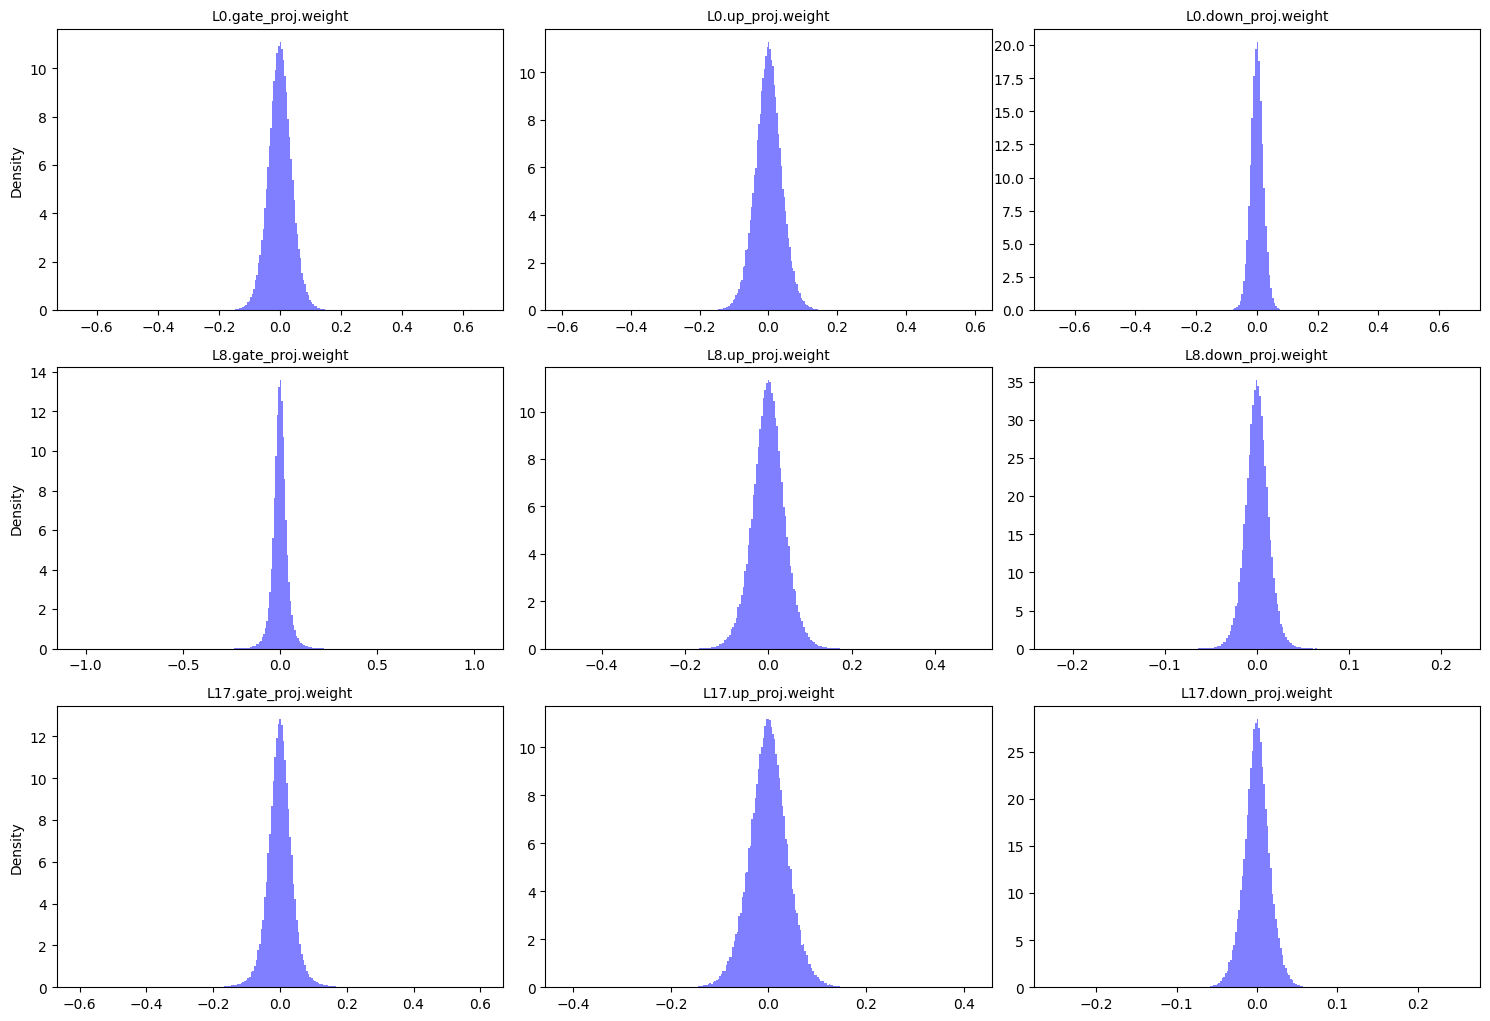

In [12]:
def plot_ffn_weight_distribution(model, bins=256, count_nonzero_only=False, layers_to_plot=[0, 8, 17]):
    ffn_params = []
    for name, param in model.named_parameters():
        if 'mlp' in name and param.dim() > 1:
            try:
                parts = name.split('.')
                if 'layers' in parts:
                    layer_idx = int(parts[parts.index('layers') + 1])
                    if layer_idx in layers_to_plot:
                        ffn_params.append((name, param))
            except (ValueError, IndexError):
                continue

    num_params = len(ffn_params)
    cols = 3
    rows = (num_params + cols - 1) // cols
    print(f"Plotting FFN weights for layers {layers_to_plot}...")

    fig, axes = plt.subplots(rows, cols, figsize=(15, 3.5 * rows))
    if isinstance(axes, np.ndarray):
        axes = axes.ravel()
    else:
        axes = [axes]

    for i, (name, param) in enumerate(ffn_params):
        ax = axes[i]
        param_data = param.detach().view(-1).cpu().float().numpy()

        if count_nonzero_only:
            param_data = param_data[param_data != 0]

        ax.hist(param_data, bins=bins, density=True, color='blue', alpha=0.5)

        max_abs = np.max(np.abs(param_data))
        ax.set_xlim(-max_abs, max_abs)

        clean_name = name.replace('model.layers.', 'L').replace('.mlp.', '.')
        ax.set_title(clean_name, fontsize=10)

        if i % cols == 0:
            ax.set_ylabel('Density')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    fig.tight_layout()
    fig.subplots_adjust(top=1.0 - (0.05 / max(1, rows/4)))
    plt.show()

plot_ffn_weight_distribution(model, layers_to_plot=[0, 8, 17])

## Question 1 (10 pts)

Please answer the following questions using the information in the above histograms of weights.

### Question 1.1 (5 pts)

Try visulizing different layers. What are the common characteristics of the weight distribution in the different layers?

**Your Answer:**

Across the different layers and FFN projections, the weight distributions share serveral common characteristics:

1. **Zero-centered:** The weights are approximately centered around 0, with mean close to zero.
2. **Symmetric:** The distributions are roughly symmetric on the positive and negative sides.
3. **Unimodal and sharply peaked:** Each histogram has a single strong peak near 0, meaning most weights have very small magnitude.
4. **Concentrated near zero:** The majority of weights lie in a narrow interval around 0, while large-magnitude weights are relatively rare.
5. **Similar qualitative shape across layers:** Although the exact range and peak height vary by layer/projection—e.g., some `down_proj` layers are narrower—the overall shape remains bell-like and zero-centered.

These characteristics suggest that many weights contribute little and can potentially be pruned by removing small-magnitude weights, which is the motivation for fine-grained pruning.

### Question 1.2 (5 pts)

How do these characteristics help pruning?

**Your Answer:**

These characteristics make pruning effective and relatively safe:

1. **Most weights are near zero:** Since the distributions are sharply peaked around 0, a large fraction of weights have very small magnitude. Such weights usually contribute little to the layer output, so removing them causes only minimal accuracy loss.
2. **Magnitude-based thresholding is natural:** Because the weights are concentrated near zero and symmetric, we can choose a small absolute-value threshold and prune all weights with $|w| < \tau$. This removes many weights while keeping the larger, more important ones.
3. **High potential sparsity:** The sharp peak implies that a large proportion of weights can be removed without touching the tails of the distribution, enabling high sparsity and significant model size reduction.
4. **Consistent behavior across layers:** The similar zero-centered, bell-like shapes across layers suggest that a similar pruning strategy or threshold rule can be applied broadly, rather than requiring very different treatment for each layer.
5. **Low risk of bias:** The roughly symmetric distributions mean small positive and negative weights are both abundant, so pruning small-magnitude weights does not strongly bias the remaining weights towards one sign.

Overall, these properties support **fine-grained magnitude pruning**: prune small weights according to a threshold, achieving sparsity with limited impact on perplexity.

# Fine-grained Pruning

In this section, we will implement and perform fine-grained pruning.

Fine-grained pruning removes the synapses with lowest importance. The weight tensor $W$ will become sparse after fine-grained pruning, which can be described with **sparsity**:

> $\mathrm{sparsity} := \#\mathrm{Zeros} / \#W = 1 - \#\mathrm{Nonzeros} / \#W$

where $\#W$ is the number of elements in $W$.

In practice, given the target sparsity $s$, the weight tensor $W$ is multiplied with a binary mask $M$ to disregard removed weight:

> $v_{\mathrm{thr}} = \texttt{kthvalue}(Importance, \#W \cdot s)$
>
> $M = Importance > v_{\mathrm{thr}}$
>
> $W = W \cdot M$

where $Importance$ is importance tensor with the same shape of $W$, $\texttt{kthvalue}(X, k)$ finds the $k$-th smallest value of tensor $X$, $v_{\mathrm{thr}}$ is the threshold value.

## Magnitude-based Pruning

For fine-grained pruning, a widely-used importance is the magnitude of weight value, *i.e.*,

$Importance=|W|$

This is known as **Magnitude-based Pruning** (see [Learning both Weights and Connections for Efficient
Neural Networks](https://arxiv.org/pdf/1506.02626.pdf)).

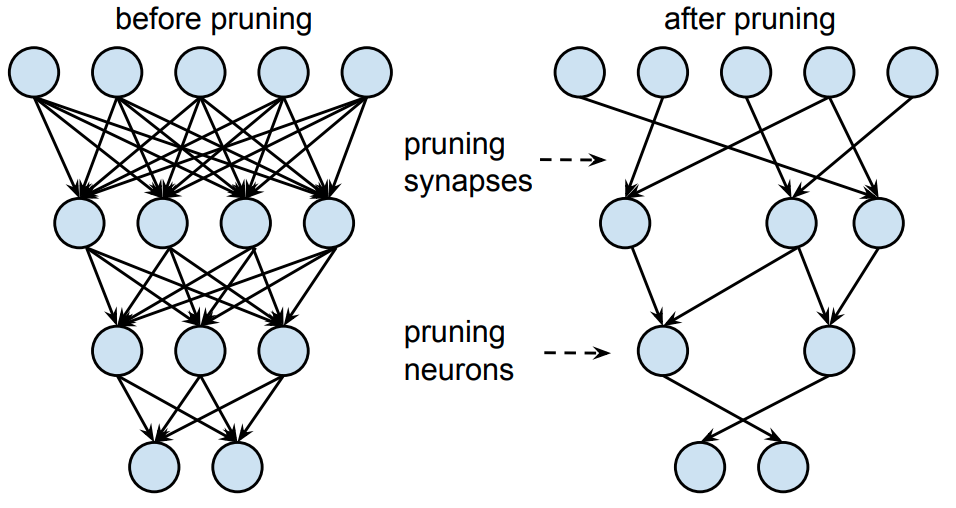

## Question 2 (15 pts)

Please complete the following magnitude-based fine-grained pruning function.

**Hint**:
*   In step 1, we calculate the number of zeros (`num_zeros`) after pruning. Note that `num_zeros` should be an integer. You could use either `round()` or `int()` to convert a floating number into an integer. Here we use `round()`.
*   In step 2, we calculate the `importance` of weight tensor. Pytorch provides [`torch.abs()`](https://pytorch.org/docs/stable/generated/torch.abs.html#torch.abs), [`torch.Tensor.abs()`](https://pytorch.org/docs/stable/generated/torch.Tensor.abs.html#torch.Tensor.abs), [`torch.Tensor.abs_()`](https://pytorch.org/docs/stable/generated/torch.Tensor.abs_.html) APIs.
*   In step 3, we calculate the pruning `threshold` so that all synapses with importance smaller than `threshold` will be removed. Pytorch provides [`torch.kthvalue()`](https://pytorch.org/docs/stable/generated/torch.kthvalue.html), [`torch.Tensor.kthvalue()`](https://pytorch.org/docs/stable/generated/torch.Tensor.kthvalue.html), [`torch.topk()`](https://pytorch.org/docs/stable/generated/torch.topk.html) APIs.
*   In step 4, we calculate the pruning `mask` based on the `threshold`. **1** in the `mask` indicates the synapse will be kept, and **0** in the `mask` indicates the synapse will be removed. `mask = importance > threshold`. Pytorch provides [`torch.gt()`](https://pytorch.org/docs/stable/generated/torch.gt.html?highlight=torch%20gt#torch.gt) API.

In [13]:
def fine_grained_prune(tensor: torch.Tensor, sparsity : float) -> torch.Tensor:
    """
    magnitude-based pruning for single tensor
    :param tensor: torch.(cuda.)Tensor, weight of conv/fc layer
    :param sparsity: float, pruning sparsity
        sparsity = #zeros / #elements = 1 - #nonzeros / #elements
    :return:
        torch.(cuda.)Tensor, mask for zeros
    """
    sparsity = min(max(0.0, sparsity), 1.0)
    if sparsity == 1.0:
        tensor.zero_()
        return torch.zeros_like(tensor)
    elif sparsity == 0.0:
        return torch.ones_like(tensor)

    num_elements = tensor.numel()
    ##################### YOUR CODE STARTS HERE #####################
    # Step 1: calculate the #zeros
    num_zero = round(num_elements * sparsity)

    # Step 2: calculate the importance of weight
    importance = tensor.abs()

    # Step 3: calculate the pruning threshold
    threshold = importance.view(-1).kthvalue(num_zero).values

    # Step 4: get binary mask (1 for nonzeros, 0 for zeros)
    mask = importance > threshold

    ##################### YOUR CODE ENDS HERE #####################

    # Step 5: apply mask to prune the tensor
    tensor.mul_(mask)

    return mask

Let's verify the functionality of defined fine-grained pruning by applying the function above on a dummy tensor.

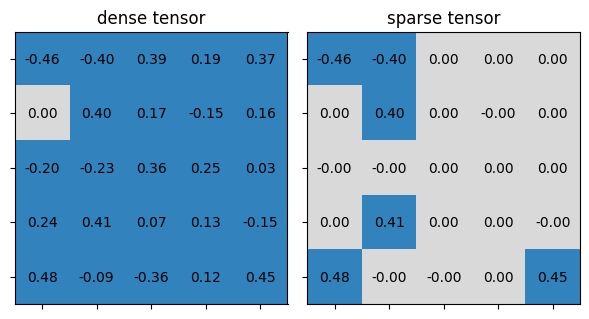

* Test fine_grained_prune()
    target sparsity: 0.75
        sparsity before pruning: 0.04
        sparsity after pruning: 0.76
        sparsity of pruning mask: 0.76
* Test passed.


In [14]:
test_fine_grained_prune()

## Question 3 (self-check, not graded)

The last cell plots the tensor before and after pruning. Nonzeros are rendered in blue while zeros are rendered in gray. Please modify the value of `target_sparsity` in the following code cell so that there are only 10 nonzeros in the sparse tensor after pruning.

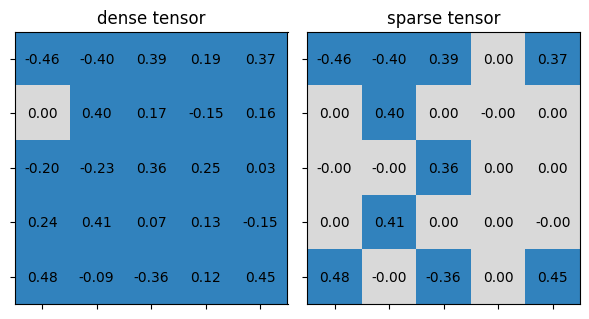

* Test fine_grained_prune()
    target sparsity: 0.60
        sparsity before pruning: 0.04
        sparsity after pruning: 0.60
        sparsity of pruning mask: 0.60
* Test passed.


In [15]:
##################### YOUR CODE STARTS HERE #####################
target_sparsity = 0.6 # please modify the value of target_sparsity
##################### YOUR CODE ENDS HERE #####################
test_fine_grained_prune(target_sparsity=target_sparsity, target_nonzeros=10)

We now wrap the fine-grained pruning function into a class for pruning the whole model. In class `FineGrainedPruner`, we have to keep a record of the pruning masks so that we could apply the masks whenever the model weights change to make sure the model keep sparse all the time.

In [16]:
class FineGrainedPruner:
    def __init__(self, model, sparsity_list):
        self.masks = FineGrainedPruner.prune(model, sparsity_list)

    @torch.no_grad()
    def apply(self, model):
        for name, param in model.named_parameters():
            if name in self.masks:
                param.mul_(self.masks[name])

    @staticmethod
    @torch.no_grad()
    def prune(model, sparsity_list):
        masks = dict()
        for name, param in model.named_parameters():
            if 'mlp' in name and param.dim() > 1:
                parts = name.split('.')
                layer_idx = int(parts[parts.index('layers') + 1])
                masks[name] = fine_grained_prune(param, sparsity=sparsity_list[layer_idx])
        return masks

## Sensitivity Scan


Different layers contribute differently to the model performance. It is challenging to decide the proper sparsity for each layer. A widely used approach is sensitivity scan.

During the sensitivity scan, at each time, we will only prune one layer to see the perplexity change. By scanning different sparsities, we could draw the sensitivity curve (i.e., ppl vs. sparsity) of the corresponding layer.


The following code cell defines the sensitivity scan function that returns the sparsities scanned, and a list of PPL for each layer to be pruned. For simplicity, we set the three weights matrix in the same layer the same sparse ratio.

In [17]:
@torch.no_grad()
def sensitivity_scan_ffn_gemma(model, tokenizer, scan_step=0.1, scan_start=0.4, scan_end=1.0, verbose=True):
    sparsities = np.arange(start=scan_start, stop=scan_end, step=scan_step)
    perplexities = []
    ffn_layers = {}
    for name, param in model.named_parameters():
        if 'mlp' in name and param.dim() > 1:
            parts = name.split('.')
            layer_idx = int(parts[parts.index('layers') + 1])
            ffn_layers.setdefault(layer_idx, []).append((name, param))

    sorted_layer_ids = sorted(ffn_layers.keys())
    print(f"Scanning {len(sorted_layer_ids)} layers")

    # 2. Scan each layer
    for layer_id in sorted_layer_ids:
        weights = ffn_layers[layer_id]
        weight_clones = {name: param.detach().clone() for name, param in weights}
        ppl_list = []

        if verbose:
            print(f'Scanning Layer {layer_id}... ', end='')

        for sparsity in sparsities:
            # Apply pruning to all FFN weights in this layer
            for name, param in weights:
                fine_grained_prune(param.detach(), sparsity=sparsity)

            # Fast Evaluate
            ppl = evaluate(model)
            ppl_list.append(ppl)

            # Restore original weights
            for name, param in weights:
                param.copy_(weight_clones[name])

        if verbose:
            # Print condensed results for the layer
            best_ppl = min(ppl_list)
            worst_ppl = max(ppl_list)
            print(f'PPL Range: {best_ppl:.2f} -> {worst_ppl:.2f}')

        perplexities.append(ppl_list)

    return sparsities, perplexities

Please run the following cells to plot the sensitivity curves.

In [18]:
sparsities, perplexities = sensitivity_scan_ffn_gemma(model, tokenizer, scan_step=0.1, scan_start=0.4, scan_end=0.9)

Scanning 18 layers
Scanning Layer 0... 

PPL Range: 57.27 -> 103.62
Scanning Layer 1... 

PPL Range: 54.80 -> 69.82
Scanning Layer 2... 

PPL Range: 55.59 -> 74.10
Scanning Layer 3... 

PPL Range: 53.13 -> 113.61
Scanning Layer 4... 

...

PPL Range: 57.30 -> 61.56
Scanning Layer 14... 

PPL Range: 60.27 -> 71.02
Scanning Layer 15... 

PPL Range: 59.09 -> 84.17
Scanning Layer 16... 

PPL Range: 57.57 -> 69.40
Scanning Layer 17... 

PPL Range: 60.00 -> 141.53


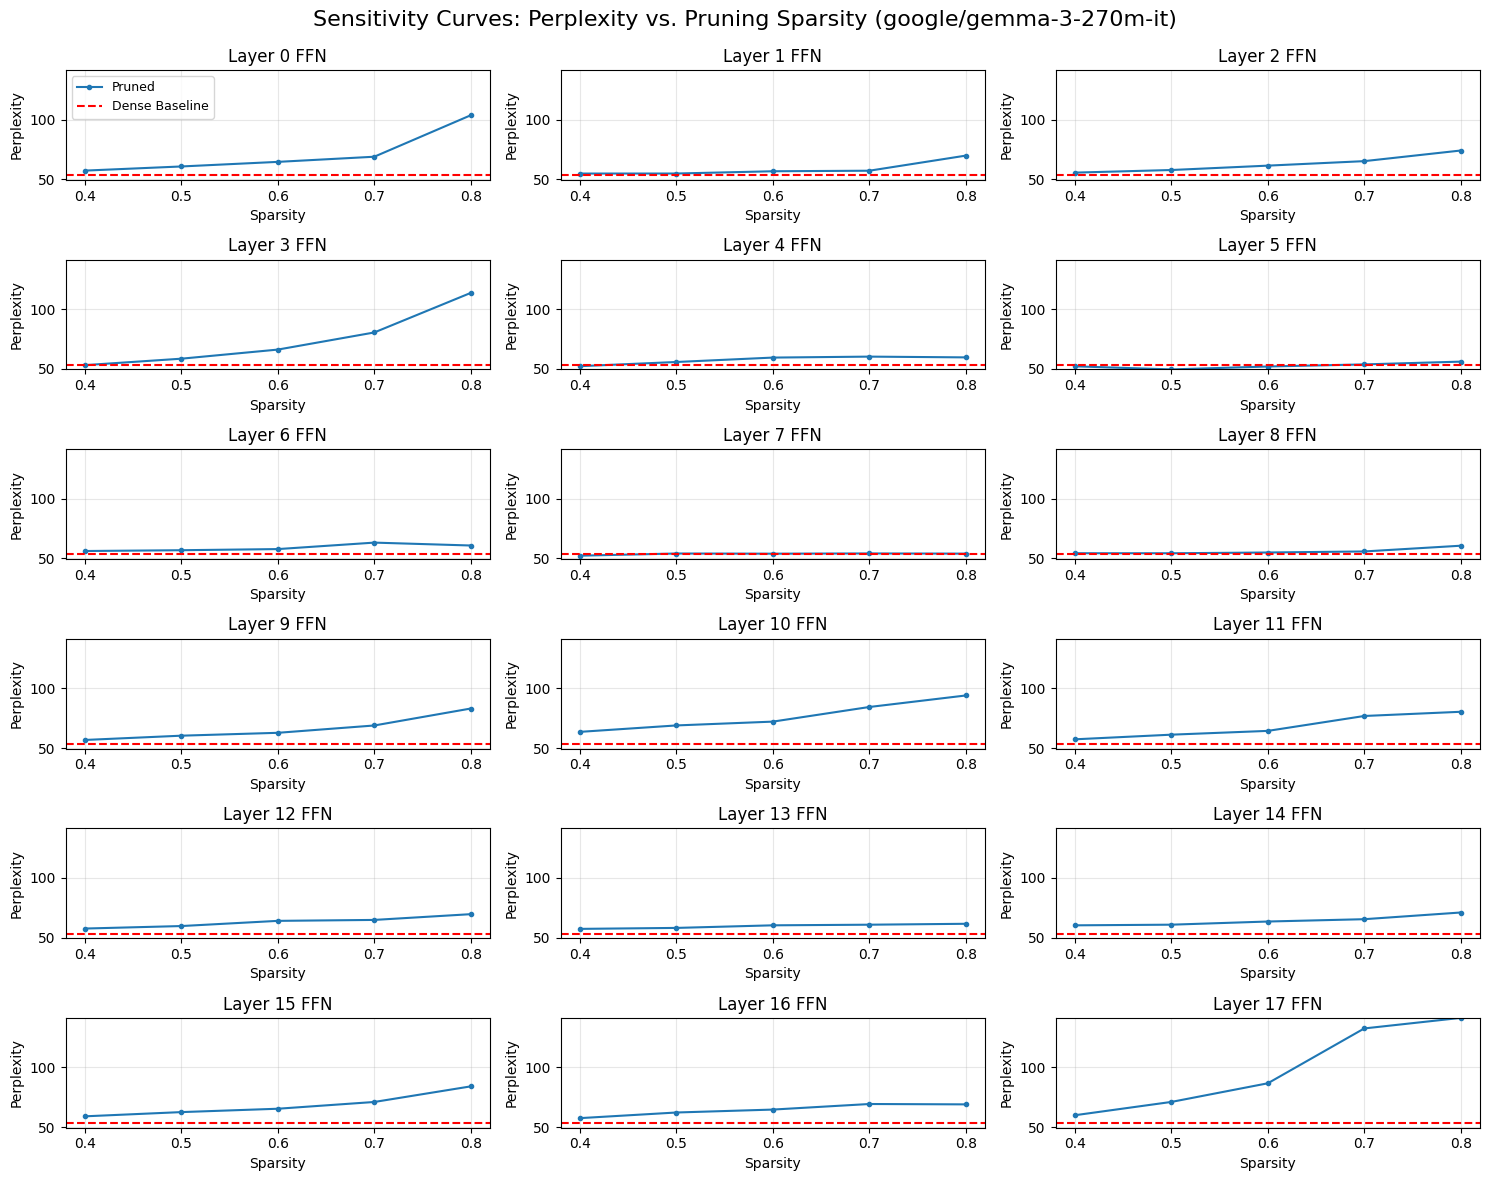

In [19]:
def plot_sensitivity_scan_ppl(sparsities, perplexities, dense_model_ppl):
    num_layers = len(perplexities)
    n_rows = 6
    n_cols = math.ceil(num_layers / n_rows)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 12))
    axes = axes.ravel()

    all_ppls = [p for ppl_list in perplexities for p in ppl_list]
    y_min = min(all_ppls + [dense_model_ppl])
    y_max = max(all_ppls + [dense_model_ppl])

    for i, ppl_list in enumerate(perplexities):
        ax = axes[i]
        ax.plot(sparsities, ppl_list, marker='.', linestyle='-', linewidth=1.5, label='Pruned')
        ax.axhline(dense_model_ppl, color='r', linestyle='--', linewidth=1.5, label='Dense Baseline')
        ax.set_ylim([y_min, y_max])
        ax.set_xticks(np.round(sparsities, 1))
        ax.set_title(f'Layer {i} FFN', fontsize=12)
        ax.set_xlabel('Sparsity')
        ax.set_ylabel('Perplexity')
        ax.grid(True, alpha=0.3)
        if i == 0:
            ax.legend(fontsize=9)

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f'Sensitivity Curves: Perplexity vs. Pruning Sparsity ({model_id})', fontsize=16)
    fig.tight_layout()
    fig.subplots_adjust(top=0.93)
    plt.show()

plot_sensitivity_scan_ppl(sparsities, perplexities, dense_model_perplexity)

## Question 4 (15 pts)

Please answer the following questions using the information in the above sensitivity curves.

### Question 4.1 (5 pts)

What's the relationship between pruning sparsity and PPL? (*i.e.*, does PPL increase or decrease when sparsity becomes higher?)

**Your Answer:**

Overall, perplexity (PPL) **increases as pruning sparsity becomes higher**. The relationship is generally **positive but nonliner**:

- At relatively low sparsity, PPL stays close to the dense baseline, meaning the model is fairly robust to pruning a moderate fraction of small-magnitude weights.
- As sparsity continues to increase, PPL begins to rise, and beyond a certain point it grows **sharply**, including that too many important weights have been removed.
- The sensitivity differs across layers: some layers (e.g., Layer 17) degrade much faster, with PPL rising from about 60 to about 141.53, while other layers remian relatively stable until higher sparsity.

So, higher sparsity generally leads to higher PPL, and the increase accelerates at high sparsity levels.

### Question 4.2 (5 pts)

Do all the layers have the same sensitivity?

**Your Answer:**

No, not all layers have the same sensitivity. The sensitivity curves show clear differences across layers:

- Some layers are relatively **robust** to pruning. For example, Layers 4, 5, 7, and 8 stay close to the dense baseline even at high sparsity, with only small PPL increases.
- Other layers are much more **sensitive**. For example, Layer 17 degrades severely, with PPL rising from about 60 to about 141.53; Layers 0, 3, 9, 10, 11, and 15 also show noticeable PPL increases as sparsity grows.
- The point at which PPL starts to rise sharply also differs by layer.

Therefore, different layers have different pruning sensitivity, which suggests that we should assign different sparsity levels to different layers rather than using a uniform sparsity for all of them.

### Question 4.3 (5 pts)

Which layer is the most sensitive to the pruning sparsity?

**Your Answer:**

**Layer 17 is the most sensitive layer to pruning sparsity**. Its sensitivity curve rises most sharply as sparsity increases: the PPL goes from about 60.00 to about 141.53, which is the largest degradation among all FFN layers shown. This indicates that Layer 17 contains more important weights and is much less tolerant to aggressive pruning than the other layers.

## Select Sparsity Based on Sensitivity Curves



## Question 5 (exploration, not graded)

Based on the sensitivity curves, try selecting a sparsity for each layer. A reasonable
starting point is provided in the next cell -- feel free to explore other combinations.

See how close you can get while keeping the sparse model under 90% of the dense model's
size and the perplexity below the dense baseline after finetuning.

In [20]:
recover_model()
# sparsity_list = [0.1, 0.5, 0.1, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.4, 0.5, 0.1]

# The optimal sparsity list discovered
sparsity_list = [0.3, 0.3, 0.2, 0.0, 0.7, 0.5, 0.4, 0.4, 0.6, 0.2, 0.2, 0.2, 0.7, 0.7, 0.4, 0.2, 0.6, 0.3]

### Exploration (not graded)

Could you write a grid search script to automatically find the optimal sparsity list?

#### Exploratory: random sparsity search (not executed)

> **Note:** This cell is kept for reference only. It was an exploratory search used while choosing the per-layer sparsity list in cell 63. It is **not executed** in the final notebook: running it would mutate the model and make the saved cells 67-72 non-reproducible. The final run uses the hard-coded list in cell 63.

```python
import random

def evalue_sparsity(sparsity_list):
    recover_model()
    pruner = FineGrainedPruner(model, sparsity_list)
    size = get_model_size(model, count_nonzero_only=True)
    ppl = evaluate(model)
    return size, ppl

# Sensitive layers get lower sparsity, roubust layers get higher sparsity
sensitive_layers = {0, 2, 3, 9, 10, 11, 15, 17}
best_ppl, best_list, best_size = float('inf'), None, None

for _ in range(20):
    sparsity_list = []
    for i in range(18):
        if i in sensitive_layers:
            sparsity_list.append(random.choice([0.0, 0.1, 0.2, 0.3]))
        else:
            sparsity_list.append(random.choice([0.3, 0.4, 0.5, 0.6, 0.7]))

    size, ppl = evalue_sparsity(sparsity_list)
    # Constraint: under 90% of dense size
    if size / dense_model_size < 0.90 and ppl < best_ppl:
        best_ppl, best_list, best_size = ppl, sparsity_list, size

print("Best sparsity list:", best_list)
print(f"Size: {best_size / MiB:.2f} MiB ({best_size/dense_model_size*100:.2f}%)")
print(f"PPL before finetuning: {best_ppl:.2f}")
```


Please run the following cell to prune the model according to your defined `sparsity_list`, and print the information of sparse model.

Sparse model has size=918.98 MiB = 89.86% of dense model size


Sparse model has perplexity=214.46 before finetuning
Plotting FFN weights for layers [0, 8, 17]...


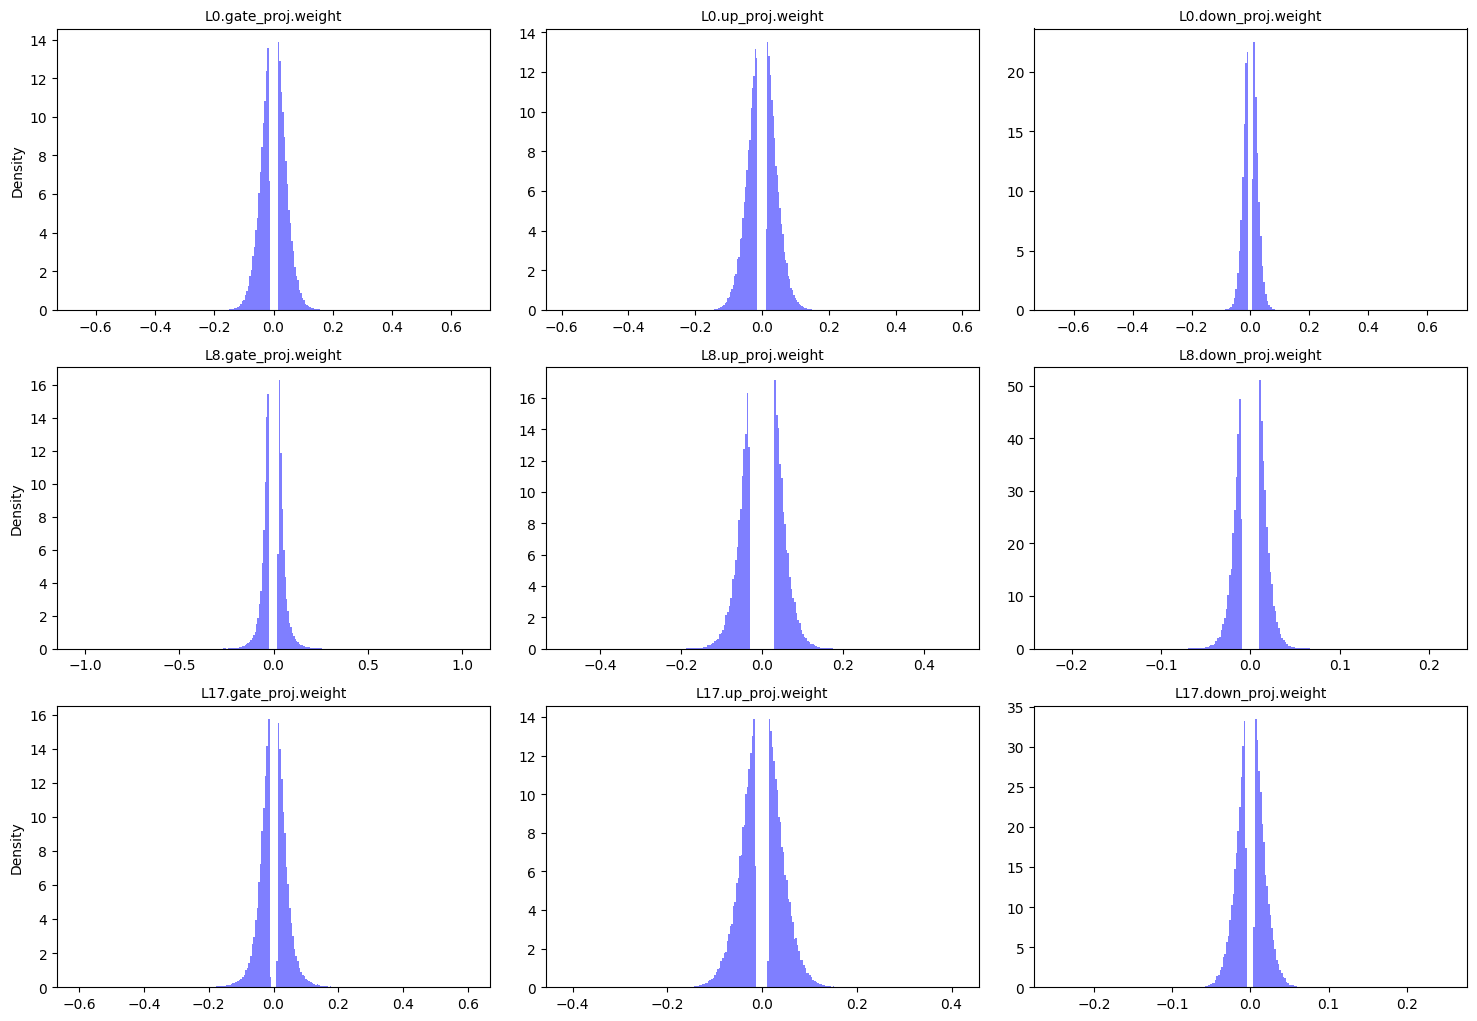

In [21]:
pruner = FineGrainedPruner(model, sparsity_list)
sparse_model_size = get_model_size(model, count_nonzero_only=True)
print(f"Sparse model has size={sparse_model_size / MiB:.2f} MiB = {sparse_model_size / dense_model_size * 100:.2f}% of dense model size")
sparse_model_perplexity = evaluate(model)
print(f"Sparse model has perplexity={sparse_model_perplexity:.2f} before finetuning")

plot_ffn_weight_distribution(model, count_nonzero_only=True)

## Finetune the fine-grained pruned model

As we can see from the outputs of previous cell, even though fine-grained pruning reduces the model weights, the perplexity of model also increases. Therefore, we have to finetune the sparse model to recover the perplexity.

Please run the following cell to finetune the sparse model.

In [22]:
model = train(
    model,
    tokenizer,
    pruner=pruner,
    num_steps=30,
    lr=1e-4
)


Training for 30 steps to recover performance...


Training: 100%|██████████| 30/30 [00:09<00:00,  3.18it/s, loss=4.14]


Run the following cell to see the information of the finetuned sparse model.

In [23]:
# load the best sparse model checkpoint to evaluate the final performance
sparse_model_size = get_model_size(model, count_nonzero_only=True)
print(f"Sparse model has size={sparse_model_size / MiB:.2f} MiB = {sparse_model_size / dense_model_size * 100:.2f}% of dense model size")
sparse_model_ppl = evaluate(model)
print(f"Sparse model has perplexity={sparse_model_ppl:.2f} after finetuning")

Sparse model has size=918.98 MiB = 89.86% of dense model size


Sparse model has perplexity=41.61 after finetuning


## Wanda Pruning (Weights and Activations)

Magnitude-based pruning assumes that weights with small values are less important. However, in Large Language Models (LLMs), some weights might be small but process extremely large input features (activations), making them critical for the model's output.

**Wanda** (Pruning by **W**eights **and** **A**ctivations) addresses this by defining importance as the product of the weight magnitude and the L2 norm of its corresponding input activation:

$$Importance_{ij} = |W_{ij}| \cdot ||X_j||_2$$

where $W_{ij}$ is the weight connecting input $j$ to output $i$, and $X_j$ is the activation of input feature $j$. This method effectively handles the "massive activation outliers" common in Transformers (see [A Simple and Effective Pruning Approach for Large Language Models](https://arxiv.org/abs/2306.11695)).

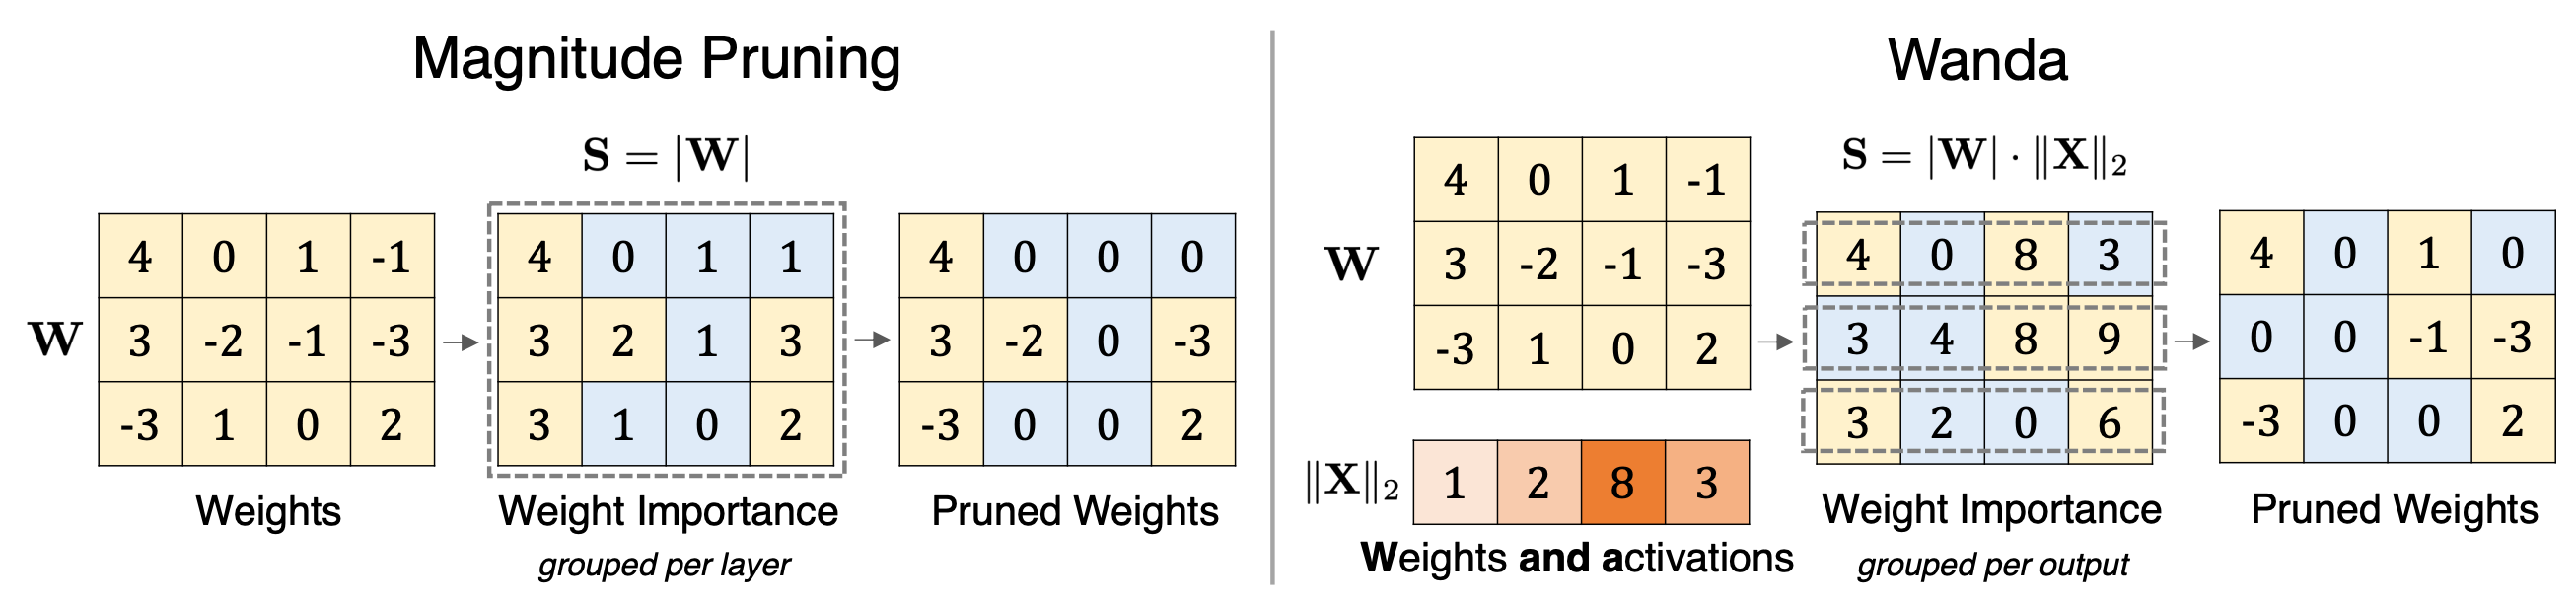

## Question 6 (15 pts)

Please finish the Wanda mask computation part in the prune function.

In [24]:
class WandaPruner:
    def __init__(self, model, tokenizer, sparsity=0.5, num_samples=128):
        layers = model.model.layers
        sparsity_list = [sparsity] * len(layers)
        self.masks = self.prune(model, tokenizer, sparsity_list, num_samples)

    @torch.no_grad()
    def apply(self, model):
        print("Applying Wanda Pruning masks...")
        for name, param in model.named_parameters():
            if name in self.masks:
                param.data.mul_(self.masks[name])

    @staticmethod
    def prune(model, tokenizer, sparsity_list, num_samples=128):
        print(f"1. Wanda Calibration with {num_samples} tokens...")
        model.eval()
        act_norms = {}
        hooks = []

        # --- A. Hook Function to capture activation norms ---
        def hook_fn(module_name, module, args, output):
            inp = args[0].detach().float()
            if inp.dim() == 2: # [Batch*Seq, Hidden]
                 current_norm = inp.pow(2).sum(dim=0)
            else: # [Batch, Seq, Hidden]
                 current_norm = inp.pow(2).sum(dim=(0, 1))

            if module_name not in act_norms:
                act_norms[module_name] = current_norm
            else:
                act_norms[module_name] += current_norm

        # --- B. Register Hooks on all MLP Linear layers ---
        linear_layers = {}
        layers = model.model.layers if hasattr(model, 'model') else model.layers

        for i, layer in enumerate(layers):
            mlp = layer.mlp
            modules = {
                f"model.layers.{i}.mlp.gate_proj": mlp.gate_proj,
                f"model.layers.{i}.mlp.up_proj": mlp.up_proj,
                f"model.layers.{i}.mlp.down_proj": mlp.down_proj
            }
            for name, module in modules.items():
                linear_layers[name] = module
                hooks.append(module.register_forward_hook(partial(hook_fn, name)))

        calib_data = test_encodings.input_ids[:, :num_samples].to(model.device)

        with torch.no_grad():
            model(calib_data)
        for h in hooks: h.remove()

        print(f"2. Computing Wanda Masks...")
        masks = {}
        for name, module in linear_layers.items():
            parts = name.split('.')
            try:
                layer_idx = int(parts[parts.index('layers') + 1])
            except:
                continue

            if layer_idx >= len(sparsity_list): continue
            target_sparsity = sparsity_list[layer_idx]

            mask = None

            ##################### YOUR CODE STARTS HERE #####################
            # Step 1: L2 norm of input activations (hook stored squared sum)
            act_norm = act_norms[name].sqrt()          # [in_features]

            # Step 2: Wanda importance = |W| * ||X||_2
            W = module.weight.data.float()             # [out_features, in_features]
            importance = W.abs() * act_norm.unsqueeze(0)

            # Step 3: per-output-row pruning (Wanda keeps top-k in each row)
            in_features = W.shape[1]
            num_keep = int(round(in_features * (1.0 - target_sparsity)))
            num_keep = max(0, min(num_keep, in_features))

            if num_keep == 0:
                mask = torch.zeros_like(module.weight)
            elif num_keep == in_features:
                mask = torch.ones_like(module.weight)
            else:
                topk_indices = torch.topk(importance, num_keep, dim=1).indices
                mask = torch.zeros_like(module.weight)
                mask.scatter_(1, topk_indices, 1)
            ##################### YOUR CODE ENDS HERE #####################
            masks[name+".weight"] = mask

        return masks

In [25]:
recover_model()
# Run the fixed function
target_sparsity = 0.6
print(f"\n=== Wanda Unstructured (Fine-Grained) @ {target_sparsity:.0%} ===")
pruner = WandaPruner(model, tokenizer, sparsity=target_sparsity, num_samples=128)
pruner.apply(model)
ppl_fg = evaluate(model)
print(f"Fine-Grained Wanda PPL: {ppl_fg:.2f}")


=== Wanda Unstructured (Fine-Grained) @ 60% ===
1. Wanda Calibration with 128 tokens...
2. Computing Wanda Masks...
Applying Wanda Pruning masks...


Fine-Grained Wanda PPL: 116.09


## Question 7 (10 pts)

Compare the activation-aware and weight-magnitude based pruned model before fine-tune, which one performs better? Read the paper of Wanda and briefly explain the reason.

**Your Answer:**

The activation-aware Wanda pruner performs better than weight-magnitude pruning before fine-tuning. In this lab, Wanda at **60% uniform FFN sparsity** reaches a PPL of **116.09**, while the magnitude-based run with the sensitivity-tuned, non-uniform sparsity list (about **38.3% average FFN sparsity** and **89.86%** of dense model size) reaches **214.46**. The two runs do not use the same sparsity budget; Wanda is actually pruned more aggressively, yet it still has the lower PPL, which makes the activation-aware advantage even stronger. A fully controlled comparison would apply the same per-layer budget to both criteria; the numbers above show the qualitative effect, not an exact matched-sparsity gap.

The reason lies in how Wanda redefines "importance" for LLMs:

- **Magnitude pruning ignores activations.** It assumes small weights are unimportant, but this assumption breaks in LLMs. A weight can be numerically small yet repeatedly multiplied by extremely large input activations, making it functionally critical. Magnitude pruning would wrongly remove such weights.
- **LLMs contain "massive activation outliers."** Research shows that a small subset of hidden features in LLMs have magnitudes roughly 100 times larger than typical values, and zeroing them out causes severe performance degradation. Weights connected to these outlier features are indispensable even if their own magnitudes are modest.
- **Wanda corrects this blind spot.** Its importance score is $\text{Importance}_{ij} = |W_{ij}| \cdot \|X_j\|_2$: the product of weight magnitude and the L2 norm of the corresponding input activation. This captures both "how large the weight is" and "how heavily that input feature is used".
- **Per-output pruning further protects useful connections.** Wanda compares importance scores **within each output row**, not globally across the whole matrix. This ensures every output neuron retains its relatively most important inputs, preventing a few globally large weights from dominating the pruning decision.

In short, magnitude pruning overlooks activation outliers unique to LLMs, while Wanda explicitly incorporates activation information, so it preserves the connections that actually matter for the model's forward pass—hence the lower pre-finetuning perplexity.


# Channel Pruning

In this section, we will implement the channel pruning. Channel pruning removes an entire channel, so that it can achieve inference speed up on existing hardware like GPUs. Similarly, we remove the channels whose weights are of smaller magnitudes (measured by Frobenius norm).

In [26]:
# firstly, let's restore the model weights to the original dense version and check the PPL
recover_model()
dense_model_ppl = evaluate(model)
print(f"dense model has perplexity={dense_model_ppl:.2f}")
print(generate_sample_text(model, tokenizer, "Robert Boulter is an English film , television and theatre actor .", max_length=32))

dense model has perplexity=53.36
Robert Boulter is an English film , television and theatre actor . He is known for his work in the film industry, particularly in the genre of film and


## Remove Channel Weights

Unlike fine-grained pruning, we can remove the weights entirely from the tensor in channel pruning. That is to say, the number of output channels is reduced:

> $\#\mathrm{out\_channels}_{\mathrm{new}} = \#\mathrm{out\_channels}_{\mathrm{origin}} \cdot (1 - \mathrm{sparsity})$

The weight tensor $W$ is still dense after channel pruning. Thus, we will refer to *sparsity* as ***prune ratio***.

Like fine-grained pruning, we can use different pruning rates for different layers. However, we use a uniform pruning rate for all the layers for now.

## Ranking Channels by Importance

Similar to fine-grained pruning, we need to find the **less important** channel weights to remove. A popular criterion for importance is to use the Frobenius norm of the weights corresponding to each input channel:

> $importance_{i} = \|W_{i}\|_2, \;\; i = 0, 1, 2,\cdots, \#\mathrm{in\_channels}-1$

We can sort the channel weights from more important to less important, and then keep the frst $k$ channels for each layer.

## Question 8 (10 pts)

Please complete the get_magnitude_importance funtion.

In [27]:
def apply_structured_pruning(model, importance_dict, prune_ratio):
    """
    Generic function to prune based on a dictionary of importance scores.
    importance_dict: {layer_idx: tensor_of_scores_per_neuron}
    """
    pruned_model = copy.deepcopy(model)
    layers = pruned_model.model.layers
    kept_count = 0
    total_count = 0

    for i, layer in enumerate(layers):
        if i not in importance_dict: continue
        mlp = layer.mlp
        scores = importance_dict[i]
        n_original = scores.numel()
        n_keep = int(round(n_original * (1.0 - prune_ratio)))
        if n_keep >= n_original: continue
        _, keep_indices = torch.topk(scores, k=n_keep, sorted=False)
        keep_indices, _ = torch.sort(keep_indices)
        mlp.gate_proj.weight.data = mlp.gate_proj.weight.data.index_select(0, keep_indices)
        mlp.up_proj.weight.data = mlp.up_proj.weight.data.index_select(0, keep_indices)
        mlp.down_proj.weight.data = mlp.down_proj.weight.data.index_select(1, keep_indices)
        if mlp.gate_proj.bias is not None:
            mlp.gate_proj.bias.data = mlp.gate_proj.bias.data.index_select(0, keep_indices)
        if mlp.up_proj.bias is not None:
            mlp.up_proj.bias.data = mlp.up_proj.bias.data.index_select(0, keep_indices)
        mlp.gate_proj.out_features = n_keep
        mlp.up_proj.out_features = n_keep
        mlp.down_proj.in_features = n_keep
        kept_count += n_keep
        total_count += n_original
    print(f"Pruned to {kept_count}/{total_count} neurons ({(kept_count/total_count):.1%} kept)")
    return pruned_model

def get_magnitude_importance(model):
    importances = {}
    layers = model.model.layers if hasattr(model, 'model') else model.layers
    for i, layer in enumerate(layers):
        ##################### YOUR CODE STARTS HERE #####################
        gate_w = layer.mlp.gate_proj.weight.data.float()   # [intermediate, hidden]
        up_w   = layer.mlp.up_proj.weight.data.float()     # [intermediate, hidden]
        down_w = layer.mlp.down_proj.weight.data.float()   # [hidden, intermediate]

        # Each intermediate neuron i corresponds to:
        #   - row i of gate_proj / up_proj (its output channel)
        #   - column i of down_proj        (its input channel)
        # Use the Frobenius (L2) norm of the associated weights as importance
        gate_norm = gate_w.norm(dim=1)       # [intermediate]
        up_norm   = up_w.norm(dim=1)         # [intermediate]
        down_norm = down_w.norm(dim=0)       # [intermediate]

        importances[i] = gate_norm + up_norm + down_norm
        ##################### YOUR CODE ENDS HERE #####################
    return importances

Similar to fine-grained pruning, we can also use Wanda in structured pruning.

## Question 9 (10 pts)

Please complete Wanda importance calculation.

In [28]:
@torch.no_grad()
def get_wanda_importance(model, tokenizer, num_samples=128):
    model.eval()
    act_norms = {}
    hooks = []
    print(f"Calibrating Wanda with {num_samples} tokens...")
    def hook_fn(module, args, output):
        inp = args[0].detach().float() # [Batch, Seq, Neurons]
        if module not in act_norms:
            act_norms[module] = inp.pow(2).sum(dim=(0,1))
        else:
            act_norms[module] += inp.pow(2).sum(dim=(0,1))
    layers = model.model.layers if hasattr(model, 'model') else model.layers
    for layer in layers:
        hooks.append(layer.mlp.down_proj.register_forward_hook(hook_fn))
    calib_data = get_wikitext_data(tokenizer, "test").input_ids[:, :num_samples].to(device)
    model(calib_data)
    for h in hooks: h.remove()
    # Calculate the wanda importance scores.
    wanda_importances = {}
    for i, layer in enumerate(layers):
        ##################### YOUR CODE STARTS HERE #####################
        # Activation norm of the intermediate features (input to down_proj)
        act_norm = act_norms[layer.mlp.down_proj].sqrt()  # [intermediate]

        gate_w = layer.mlp.gate_proj.weight.data.float()  # [intermediate, hidden]
        up_w   = layer.mlp.up_proj.weight.data.float()    # [intermediate, hidden]
        down_w = layer.mlp.down_proj.weight.data.float()  # [hidden, intermediate]

        # gate/up: input activations are not captured, so use weight norm per neuron
        gate_imp = gate_w.norm(dim=1)  # [intermediate]
        up_imp   = up_w.norm(dim=1)    # [intermediate]

        # down_proj: apply Wanda element-wise: then aggregate along output dim
        # Importance_{ij} = |W_{ij}| * ||X_j||_2
        down_imp = (down_w.abs() * act_norm.unsqueeze(0)).norm(dim=0)  # [intermediate]

        wanda_importances[i] = gate_imp + up_imp + down_imp
        ##################### YOUR CODE ENDS HERE #####################
    return wanda_importances

Run the following cell to test your implementation.

In [29]:
target_sparsity = 0.30
print("\n--- 1. Magnitude Pruning ---")
mag_scores = get_magnitude_importance(model)
model_mag = apply_structured_pruning(model, mag_scores, target_sparsity)
ppl_mag = evaluate(model_mag)
print(f"Magnitude Pruning PPL: {ppl_mag:.2f}")
del model_mag

print("\n--- 2. Wanda (Activation-Aware) Pruning ---")
wanda_scores = get_wanda_importance(model, tokenizer)
model_wanda = apply_structured_pruning(model, wanda_scores, target_sparsity)
ppl_wanda = evaluate(model_wanda)
print(f"Wanda Pruning PPL:     {ppl_wanda:.2f}")

print(f"\nSummary (Sparsity {target_sparsity:.0%}):")
print(f"Magnitude PPL: {ppl_mag:.2f}")
print(f"Wanda PPL:       {ppl_wanda:.2f}")


--- 1. Magnitude Pruning ---
Pruned to 25812/36864 neurons (70.0% kept)


Using the latest cached version of the dataset since wikitext couldn't be found on the Hugging Face Hub (offline mode is enabled).
Found the latest cached dataset configuration 'wikitext-2-raw-v1' at /home/zhouwenguang/project/mits65940/lab2/.cache/huggingface/datasets/wikitext/wikitext-2-raw-v1/0.0.0/b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Wed Oct 21 02:57:38 2026).


Magnitude Pruning PPL: 6312583233536.00

--- 2. Wanda (Activation-Aware) Pruning ---
Calibrating Wanda with 128 tokens...
Pruned to 25812/36864 neurons (70.0% kept)


Wanda Pruning PPL:     103.00

Summary (Sparsity 30%):
Magnitude PPL: 6312583233536.00
Wanda PPL:       103.00


Now let's evaluate the number of MAC operations of the FFN layer after pruning with 30% pruning rate.

As you may see, directly removing 30% of the channels leads to a 30% reduction of MAC operations.

In [30]:
batch_size = 1
seq_len = 1024
hidden_size = model.config.hidden_size

dummy_input = torch.randn(batch_size, seq_len, hidden_size, dtype=torch.float32, device=device)
dense_macs = get_model_macs(model.model.layers[0].mlp, dummy_input)
print(f"Dense FFN MACs: {dense_macs}")
pruned_macs = get_model_macs(model_wanda.model.layers[0].mlp, dummy_input)
print(f"Pruned FFN MACs: {pruned_macs}")
print(f"Reduction: {(dense_macs - pruned_macs) / dense_macs:.2f}")

Dense FFN MACs: 4028628992
Pruned FFN MACs: 2820827136
Reduction: 0.30


Wanda structured pruned model is much better than magnitude structured pruned model. So we will use the Wanda model for later experiment. Let's check the sample generation of it.

In [31]:
print(generate_sample_text(model_wanda, tokenizer, "Robert Boulter is an English film , television and theatre actor .", max_length=32))

Robert Boulter is an English film , television and theatre actor . He has worked on a variety of different films, television and theatre productions, including the following


As you can see, it performs well on generation. But the PPL we got is still higher than the dense model. Fortunately, we can fine-tune it to recover the PPL.

In [32]:
recovered_model = train(model_wanda, tokenizer, pruner=None, num_steps=25, lr=1e-4)
print(evaluate(recovered_model))
print(generate_sample_text(recovered_model, tokenizer, "Robert Boulter is an English film , television and theatre actor .", max_length=32))


Training for 25 steps to recover performance...


Training: 100%|██████████| 25/25 [00:07<00:00,  3.53it/s, loss=4.03]


44.59737014770508
Robert Boulter is an English film , television and theatre actor . He was born in London in 1900 and was born in London in 


## Measure acceleration from pruning

After fine-tuning, the model recovers the perplexity. You may have already learned that channel pruning is usually more difficult to recover perplexity compared to fine-grained pruning. However, it directly leads to a smaller model size and smaller computation without specialized model format. It can also run faster on GPUs. Now we compare the model size, computation, and latency of the pruned model.

In [33]:
@torch.no_grad()
def measure_latency(module, dummy_input, n_warmup=20, n_test=100):
    module.eval()
    # Warmup
    for _ in range(n_warmup):
        _ = module(dummy_input)

    # Synchronize before timing (Critical for GPU)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    # Measurement
    t1 = time.time()
    for _ in range(n_test):
        _ = module(dummy_input)

    # Synchronize after timing
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    t2 = time.time()
    return (t2 - t1) / n_test

# 1. Setup Data & Modules
layer_idx = 2 # Using layer 2 as representative
print(f"Benchmarking MLP (Layer {layer_idx})")

# Extract MLPs
mlp_original = copy.deepcopy(model.model.layers[layer_idx].mlp).to(device)
mlp_pruned = copy.deepcopy(recovered_model.model.layers[layer_idx].mlp).to(device)

for module in mlp_pruned.modules():
    if isinstance(module, nn.Linear):
        module.weight.data = module.weight.data.contiguous()

hidden_size = model.config.hidden_size
dummy_input = torch.randn(128, 128, hidden_size).to(device)

# 2. Run Benchmarks
table_template = "{:<20} {:<15} {:<15} {:<15}"
print("-" * 70)
print(table_template.format('Metric', 'Original', 'Pruned', 'Reduction'))
print("-" * 70)

# A. Latency
lat_orig = measure_latency(mlp_original, dummy_input)
lat_pruned = measure_latency(mlp_pruned, dummy_input)
print(table_template.format(
    'Latency (ms)',
    f"{lat_orig*1000:.3f}",
    f"{lat_pruned*1000:.3f}",
    f"{(lat_orig - lat_pruned)/lat_orig:.2%}"
))

# B. MACs
macs_orig = get_model_macs(mlp_original, dummy_input)
macs_pruned = get_model_macs(mlp_pruned, dummy_input)
print(table_template.format(
    'MACs (M)',
    f"{macs_orig/1e6:.2f}",
    f"{macs_pruned/1e6:.2f}",
    f"{1 - macs_pruned/macs_orig:.2%}"
))

# C. Parameters
params_orig = get_num_parameters(mlp_original)
params_pruned = get_num_parameters(mlp_pruned)
print(table_template.format(
    'Params (M)',
    f"{params_orig/1e6:.2f}",
    f"{params_pruned/1e6:.2f}",
    f"{1 - params_pruned/params_orig:.2%}"
))
print("-" * 70)

Benchmarking MLP (Layer 2)
----------------------------------------------------------------------
Metric               Original        Pruned          Reduction      
----------------------------------------------------------------------
Latency (ms)         14.791          10.658          27.95%         
MACs (M)             64458.06        45133.23        29.98%         
Params (M)           3.93            2.75            29.98%         
----------------------------------------------------------------------


## Question 10 (5 pts)

Compare the **latency reduction** with the **computation (MAC) reduction** in the table above.
Is the latency reduction larger or smaller than the MAC reduction on your GPU? Explain what
you observe.

*Hint: MAC count only measures the matrix multiplications. Think about what else the MLP
spends time on, and about whether the dense and pruned weight shapes keep the GPU equally
well utilized. Either answer can be correct -- what matters is that your explanation matches
the numbers you measured.*

**Your Answer:**

In this measurement, the **latency reduction (27.95%) is slightly smaller than the MAC reduction (29.98%)**.

This is expected because the MAC count is not a complete model of the MLP's runtime:

1. **The MAC estimate is not a pure matmul count.** `torchprofile` also counts the elementwise `gate × up` multiply, so the MLP's main elementwise operation is already included in the MAC number. The remaining uncounted work is mainly the GELU activation and the fixed input/output handling.
2. **Fixed overheads do not scale down.** Kernel launch overhead, memory allocation, and some memory traffic are only partially reduced. Even though the pruned matrices are smaller, the GPU still spends time launching kernels and moving data.
3. **GPU utilization changes with matrix shape.** The dense intermediate dimension (2048) maps well onto GPU tiles; after 30% channel pruning it becomes 1434, which is not a multiple of typical tile sizes, so the pruned matmuls may achieve slightly lower hardware efficiency per MAC. This is consistent with the measured gap: the MAC count drops 29.98% while latency drops 27.95%.

The measurement is a **Layer-2 MLP microbenchmark** with a 128×128 input, not an end-to-end model or smartphone latency. The conclusion is that structured channel pruning produces a real, close-to-proportional speedup in this microbenchmark; model-level and mobile savings will be smaller because attention, embeddings, and the LM head are not pruned.


# Compare Fine-grained Pruning and Channel Pruning


## Question 11 (10 pts)


After all experiments in this lab, you may have become familiar with both fine-grained pruning and channel pruning.

Please answer the following questions using what you have learned from the lectures and this lab.

### Question 11.1 (5 pts)

What are the advantages and disadvantages of fine-grained pruning and channel pruning? You can discuss from the perspective of compression ratio, perplexity (performance), latency, hardware support (*i.e.*, requiring specialized hardware accelerator), etc.

**Your Answer:**

**Fine-grained pruning** (magnitude / Wanda, removing individual weights):

- **Advantages:**
  - **Higher potential compression.** Individual weights can be removed, so fine-grained pruning can reach very high sparsity. In this lab, Wanda at 60% FFN sparsity reaches a pre-fine-tuning PPL of **116.09**; the magnitude-based fine-grained run with a non-uniform list (about **38.3% average FFN sparsity**, **89.86%** of dense size) reaches **214.46** before fine-tuning and **41.61** after fine-tuning.
  - **Fine-grained control of the trade-off.** You can tune the sparsity of each layer according to sensitivity curves, so important layers keep more weights.
  - **Larger achievable sparsity before accuracy collapses**, since important connections can be preserved individually.
- **Disadvantages:**
  - **Requires specialized hardware/software support.** After pruning, the weight matrix is sparse but is usually still stored as a dense tensor plus a mask, so memory and compute are not automatically reduced. Real speedup needs sparse kernels or sparse accelerators.
  - **Little or no latency reduction on standard GPUs/CPUs** without dedicated sparse support.
  - **Model size only shrinks if stored in a sparse format**; otherwise the dense storage remains.

**Channel pruning** (structured, removing entire intermediate channels):

- **Advantages:**
  - **Real speedup and size reduction on commodity hardware.** Removing whole channels physically shrinks the weight tensors, so MACs, parameters, and latency all drop together. In this lab, 30% channel pruning of the MLP gave ~30% MAC/parameter reduction and ~28% latency reduction in the **Layer-2 MLP microbenchmark**.
  - **No special format or accelerator needed.** The pruned model is still a standard dense network with smaller matrices, so it runs efficiently with ordinary libraries.
  - **Better memory-bandwidth and cache behavior**, because the matrices are genuinely smaller.
- **Disadvantages:**
  - **Coarser granularity.** Since an entire channel is removed, important individual weights inside a removed channel cannot be kept. In this lab, magnitude-based channel pruning collapsed catastrophically (PPL on the order of 1e12 at 30%), and Wanda needed fine-tuning to bring PPL from **103.00** to **44.60**.
  - **More sensitive to which channels are removed**, so importance scoring (e.g., Wanda) matters much more.
  - **Lower maximum sparsity before accuracy degrades sharply.**

**Summary:** Fine-grained pruning offers higher compression and precision in choosing weights, but it needs sparse hardware/software to realize speedup. Channel pruning gives practical, model-format-independent speedup on standard hardware but is harder to prune aggressively without hurting perplexity. These are general trade-offs; the lab runs use different sparsity budgets and model sizes, so the exact PPL numbers should not be treated as a controlled same-budget comparison.

> Note: the 30% MAC/parameter and ~28% latency numbers above are for a single MLP layer, not the full model. The FFN is only about 26% of the model's parameters, so end-to-end savings are smaller.


### Question 11.2 (5 pts)

If you want to make your model run faster on a smartphone, which pruning method will you use? Why?

**Your Answer:**

I would use **channel pruning (structured pruning)** to make the model run faster on a smartphone.

**Why:**

1. **Smartphones are general-purpose hardware without sparse accelerators.** Fine-grained pruning produces sparse weight matrices, but mobile CPUs/GPUs/NPUs usually store them as dense tensors plus a mask (or require sparse formats). Standard mobile inference frameworks cannot efficiently exploit unstructured sparsity, so the theoretical compression rarely turns into real latency reduction—index/metadata overhead can even slow things down.
2. **Channel pruning physically shrinks the matrices.** Removing entire intermediate channels reduces the actual weight dimensions, so MACs, parameters, memory footprint, and latency all drop together. The pruned model remains a standard dense network, which mobile inference engines (e.g., TFLite, NCNN, Core ML) can run directly and efficiently without special support.
3. **The lab measurements support the direction, but they are MLP-only.** For the Layer-2 MLP microbenchmark, 30% channel pruning gave about **30% MAC/parameter reduction** and **~28% latency reduction** while keeping a normal dense format. This is the kind of real speedup a smartphone needs; however, end-to-end mobile savings will be smaller because attention, embeddings, and the LM head are not pruned (the FFN is only about 26% of the model's parameters).
4. **Mobile devices are memory and power constrained.** Structured pruning reduces both memory bandwidth and energy consumption more reliably than fine-grained pruning, which is important for battery-powered devices.

**Practical note:** To limit accuracy loss, I would use an activation-aware importance criterion such as **Wanda** to decide which channels to remove, and optionally combine channel pruning with quantization or a light fine-tuning step. If even higher compression is needed, fine-grained pruning could be applied on top, but the primary method for mobile speed should be channel pruning.
